# Trusting a prediction

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/03_trusting_a_prediction.ipynb)

A cross-validated q2 is one number for the whole series. This notebook asks the questions that
number does not answer: could the fit be chance? how uncertain is q2 itself? how wide is the
interval around one prediction? and is a new molecule inside the region where the model applies?
The manual covers them in *Validation* and *Where does the model apply?*.

The data set is a synthetic benzamide series (`examples/benzamides_synthetic.sdf`, 109 aligned
molecules), whose activities were generated from known contributions, so the model has
something real to find. The notebook holds out one fifth of the molecules to play the part of new
compounds.

Running time: about a minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


In [2]:
import numpy as np
from cmfqsar import load_dataset, FieldSet, CMFModel
from cmfqsar.fields import AtomTable, build_fields
from cmfqsar.model import grid_search

ds = load_dataset("examples/benzamides_synthetic.sdf", activity_prop="pActivity")
fs = FieldSet.create()
mf = [build_fields(m, fs, n) for m, n in zip(ds.mols, ds.names)]

rng = np.random.default_rng(0)
held = np.sort(rng.choice(len(ds), size=len(ds) // 5, replace=False))
kept = np.setdiff1d(np.arange(len(ds)), held)
train = AtomTable.from_molecules([mf[i] for i in kept])
new = AtomTable.from_molecules([mf[i] for i in held])
y, y_new = ds.activity[kept], ds.activity[held]

model = CMFModel(fieldset=fs, method="krr", normalize=True)
grid_search(train, y, model, alphas=[0.5, 1.0, 2.0], lams=[1e-3, 1e-2, 0.1, 1.0])
K = model.training_kernel(train)        # the kernel matrix, kept for the checks below
model.fit(train, y, cv_folds=10)
print(model.stats.summary())

Training set: n = 88
  r2 (fit)        = 0.983    RMSE (fit)  = 0.124
  q2 (10-fold CV)  = 0.794    RMSEcv      = 0.424


## Could it be chance? y-randomisation

The activities are shuffled among the molecules and the whole procedure is repeated. A real
model's q2 must stand far above what the shuffled sets reach.

In [3]:
from cmfqsar.validation import scramble_kernel

scr = scramble_kernel(K, y, method="krr", params=model.params, runs=20)
print(scr.describe())

y-randomisation (20 shuffles, at fixed hyper-parameters): q2 (10-fold) +0.794 against -0.762 +/- 0.296 scrambled (max -0.330, z = 5.3, p = 0.048)


## How certain is q2 itself?

Resampling the (measured, predicted) pairs of the cross-validation gives a confidence interval
for q2 without refitting anything.

In [4]:
from cmfqsar.validation import bootstrap_ci

y_cv = model.stats.extra["y_cv"]
print(bootstrap_ci(y, y_cv, statistic="q2").describe())
print(bootstrap_ci(y, y_cv, statistic="rmse").describe())

q2 = +0.794, 95% bootstrap interval [+0.680, +0.863] (1000 resamples, resampling the predictions)
rmse = +0.424, 95% bootstrap interval [+0.354, +0.495] (1000 resamples, resampling the predictions)


## How certain is one prediction? Conformal intervals

The absolute errors of the cross-validation are the calibration: at level 0.9 the interval is
wide enough to have covered 90 % of them. For the held-out molecules the coverage can be checked
against their measured values.

90% conformal from 88 out-of-fold errors: half width 0.721
{'n': 21, 'coverage': 0.9047619047619048, 'mean_width': 1.441835449153988, 'median_width': 1.441835449153988}


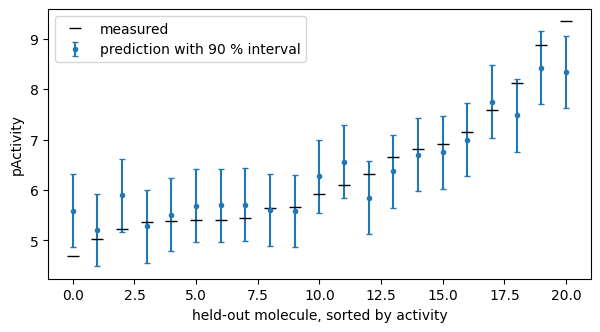

In [5]:
import matplotlib.pyplot as plt
from cmfqsar.conformal import coverage

model.calibrate_conformal(level=0.9)
print(model.conformal_.describe())
yp, lo, hi = model.predict_interval(new)
print(coverage(y_new, lo, hi))

order = np.argsort(y_new)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(np.arange(len(held)), yp[order], yerr=[yp[order] - lo[order], hi[order] - yp[order]],
            fmt="o", ms=3, capsize=2, label="prediction with 90 % interval")
ax.plot(np.arange(len(held)), y_new[order], "k_", ms=8, label="measured")
ax.set_xlabel("held-out molecule, sorted by activity"); ax.set_ylabel("pActivity"); ax.legend(); plt.show()

## Where does the model apply?

A molecule far from every training molecule in the kernel's own similarity is outside the
applicability domain, and its prediction should not be trusted whatever the interval says. The
threshold comes from the training set itself.

In [6]:
from cmfqsar.validation import domain

dom = domain(model.test_kernel(new), model.joint_self(new), K)
print(dom.describe())
print("inside:", int(dom.inside.sum()), "of", len(held))

Applicability domain (mean similarity to the 3 nearest training molecules, threshold 0.773 from the training set itself): 20/21 inside, 1 outside
inside: 20 of 21


## Is a whole library like the training set? The two-sample test

For a library rather than one molecule, the question is whether the two sets come from the same
distribution of fields. The maximum mean discrepancy test answers it with a permutation p-value;
here the held-out fifth is compared with the rest, and since it was drawn at random the test
should find no difference.

In [7]:
from cmfqsar.mmd import kernel_over, mmd_test

K_all, mask = kernel_over([ds.mols[i] for i in kept], [ds.names[i] for i in kept],
                          [ds.mols[i] for i in held], [ds.names[i] for i in held], fs)
print(mmd_test(K_all, mask, permutations=499).describe())

MMD = 0.1307 (MMD^2 = +0.01708) between 88 and 21 molecules, p = 0.2760 from 499 permutations (z = +0.3): the two sets are not distinguishable in this kernel


## The same checks from the command line

```
cmf build examples/benzamides_synthetic.sdf --y-scramble 20 --bootstrap 1000 --conformal 0.9 --domain --save benzamides.cmf
```

The next notebook, *Two endpoints and selectivity*, fits two activities at once on one kernel.